<a href="https://colab.research.google.com/github/sytluc0803/MSSP607/blob/main/Assignments/Assignment_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import userdata
import os

github_token = userdata.get('Git_Key')
owner = 'sytluc0803'
repository = 'MSSP607'

clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'

# Clone the repository
import subprocess
subprocess.run(['git', 'clone', clone_url])

# Navigate into the cloned repository directory (optional, but often useful)
os.chdir(repository)
print(f"Changed directory to: {os.getcwd()}")

Changed directory to: /content/MSSP607


In [ ]:
%pushd "/content/MSSP607/Assignments"

/content/MSSP607/Assignments


['/content/MSSP607']

In [ ]:
!ls

Assignment_01.ipynb  data_academic_performance.xlsx  README.md


In [ ]:
import numpy as np
import pandas as pd
import statistics
import matplotlib.pyplot as plt

df = pd.read_excel('data_academic_performance.xlsx')
df.head(15)

,COD_S11,GENDER,EDU_FATHER,EDU_MOTHER,OCC_FATHER,OCC_MOTHER,STRATUM,SISBEN,PEOPLE_HOUSE,Unnamed: 9,...,CC_PRO,ENG_PRO,WC_PRO,FEP_PRO,G_SC,PERCENTILE,2ND_DECILE,QUARTILE,SEL,SEL_IHE
0,SB11201210000129,F,Incomplete Professional Education,Complete technique or technology,Technical or professional level employee,Home,Stratum 4,It is not classified by the SISBEN,Three,NaN,...,71,93,79,181,180,91,5,4,2,2
1,SB11201210000137,F,Complete Secundary,Complete professional education,Entrepreneur,Independent professional,Stratum 5,It is not classified by the SISBEN,Three,NaN,...,86,98,78,201,182,92,5,4,4,4
2,SB11201210005154,M,Not sure,Not sure,Independent,Home,Stratum 2,Level 2,Five,NaN,...,18,43,22,113,113,7,1,1,1,1
3,SB11201210007504,F,Not sure,Not sure,Other occupation,Independent,Stratum 2,It is not classified by the SISBEN,Three,NaN,...,76,80,48,137,157,67,4,3,2,2
4,SB11201210007548,M,Complete professional education,Complete professional education,Executive,Home,Stratum 4,It is not classified by the SISBEN,One,NaN,...,98,100,71,189,198,98,5,4,4,2
5,SB11201210007568,F,Complete professional education,Complete professional education,Independent,Executive,Stratum 6,It is not classified by the SISBEN,Three,NaN,...,32,97,36,170,154,63,4,3,4,2
6,SB11201210007598,M,Complete professional education,Complete professional education,Small entrepreneur,Executive,Stratum 5,It is not classified by the SISBEN,Four,NaN,...,50,92,53,187,152,59,3,3,2,2
7,SB11201210007615,F,Incomplete Secundary,Complete Secundary,Entrepreneur,Independent professional,Stratum 6,It is not classified by the SISBEN,Five,NaN,...,94,97,98,188,200,99,5,4,4,4
8,SB11201210010208,M,Complete Secundary,Complete professional education,Independent,Operator,Stratum 2,It is not classified by the SISBEN,Three,NaN,...,43,3,19,177,133,28,2,2,3,2
9,SB11201210013577,M,Incomplete technical or technological,Incomplete technical or technological,Independent,Home,Stratum 2,Level 2,Four,NaN,...,22,83,1,112,126,18,1,1,4,2


In [ ]:
df.columns.tolist()

['COD_S11',
 'GENDER',
 'EDU_FATHER',
 'EDU_MOTHER',
 'OCC_FATHER',
 'OCC_MOTHER',
 'STRATUM',
 'SISBEN',
 'PEOPLE_HOUSE',
 'Unnamed: 9',
 'INTERNET',
 'TV',
 'COMPUTER',
 'WASHING_MCH',
 'MIC_OVEN',
 'CAR',
 'DVD',
 'FRESH',
 'PHONE',
 'MOBILE',
 'REVENUE',
 'JOB',
 'SCHOOL_NAME',
 'SCHOOL_NAT',
 'SCHOOL_TYPE',
 'MAT_S11',
 'CR_S11',
 'CC_S11',
 'BIO_S11',
 'ENG_S11',
 'Cod_SPro',
 'UNIVERSITY',
 'ACADEMIC_PROGRAM',
 'QR_PRO',
 'CR_PRO',
 'CC_PRO',
 'ENG_PRO',
 'WC_PRO',
 'FEP_PRO',
 'G_SC',
 'PERCENTILE',
 '2ND_DECILE',
 'QUARTILE',
 'SEL',
 'SEL_IHE']

# Descriptive Statistics for Test Scores:

High School Level: Math, Critical Reading, Cizten Competencies, English

In [ ]:
Test_S_11 = ['MAT_S11','CR_S11','CC_S11','ENG_S11']

Base_summary = df[Test_S_11].describe().T
Base_summary

,count,mean,std,min,25%,50%,75%,max
MAT_S11,12411.0,64.320764,11.873650,26.0,56.0,64.0,72.0,100.0
CR_S11,12411.0,60.778422,10.025876,24.0,54.0,61.0,67.0,100.0
CC_S11,12411.0,60.705181,10.120524,0.0,54.0,60.0,67.0,100.0
ENG_S11,12411.0,61.801064,14.297777,26.0,50.0,59.0,72.0,100.0


Histograms for S_11 Test Scores

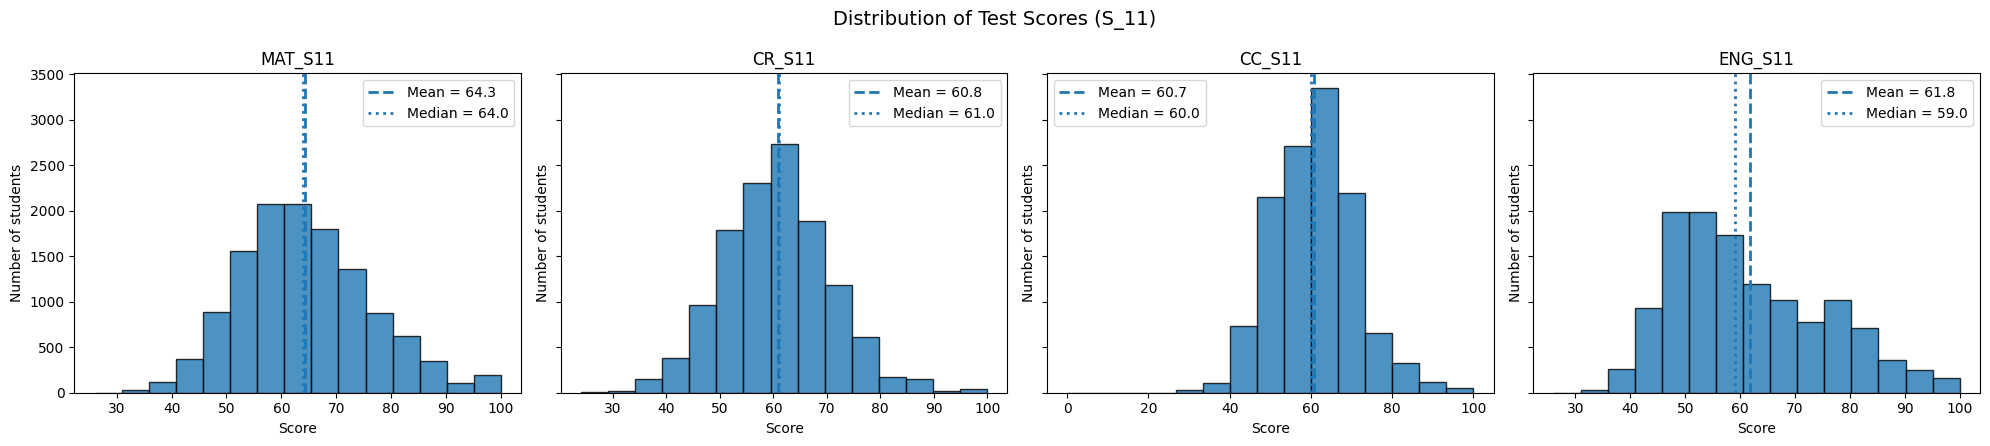

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), sharey=True)
for ax, col in zip(axes, Test_S_11):
    ax.hist(df[col], bins=15, edgecolor="black", alpha=0.8)
    ax.axvline(
        df[col].mean(),
        linestyle="--",
        linewidth=2,
        label=f"Mean = {df[col].mean():.1f}"
    )
    ax.axvline(
        df[col].median(),
        linestyle=":",
        linewidth=2,
        label=f"Median = {df[col].median():.1f}"
    )
    ax.set_title(col)
    ax.set_xlabel("Score")
    ax.set_ylabel("Number of students")
    ax.legend()

fig.suptitle("Distribution of Test Scores (S_11)", fontsize=14)

plt.tight_layout()
plt.show()

In [ ]:
Test_Pro = ['QR_PRO','CR_PRO','CC_PRO','ENG_PRO']

End_summary = df[Test_Pro].describe().T
End_summary

,count,mean,std,min,25%,50%,75%,max
QR_PRO,12411.0,77.417291,22.673444,1.0,65.0,85.0,96.0,100.0
CR_PRO,12411.0,62.199339,27.666558,1.0,42.0,67.0,86.0,100.0
CC_PRO,12411.0,59.186770,28.991840,1.0,36.0,65.0,85.0,100.0
ENG_PRO,12411.0,67.498348,25.495096,1.0,51.0,74.0,88.0,100.0


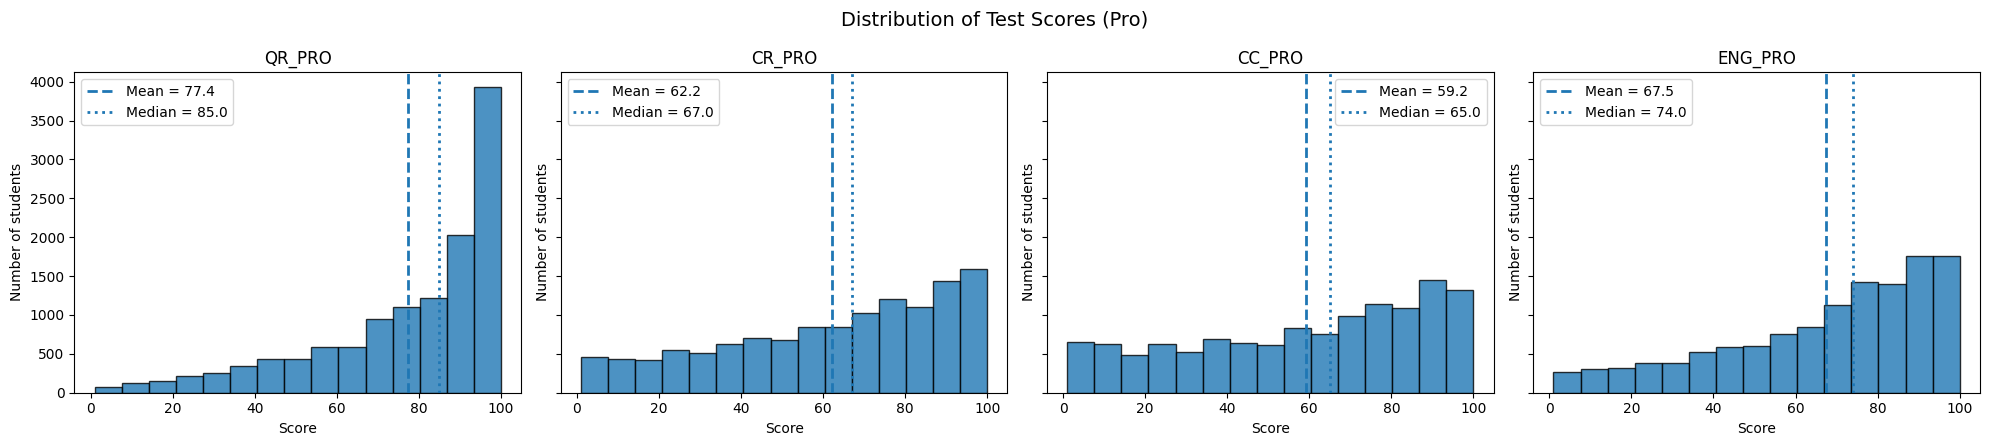

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), sharey=True)
for ax, col in zip(axes, Test_Pro):
    ax.hist(df[col], bins=15, edgecolor="black", alpha=0.8)
    ax.axvline(
        df[col].mean(),
        linestyle="--",
        linewidth=2,
        label=f"Mean = {df[col].mean():.1f}"
    )
    ax.axvline(
        df[col].median(),
        linestyle=":",
        linewidth=2,
        label=f"Median = {df[col].median():.1f}"
    )
    ax.set_title(col)
    ax.set_xlabel("Score")
    ax.set_ylabel("Number of students")
    ax.legend()

fig.suptitle("Distribution of Test Scores (Pro)", fontsize=14)

plt.tight_layout()
plt.show()

In [ ]:
df[Test_Pro].eq(1).sum()

,0
QR_PRO,12
CR_PRO,69
CC_PRO,77
ENG_PRO,31


The distribution of the test score after they earned the degree is visibly left skewed and almost show a increase across all four subjects. Overall, it indicates the engineering education put more people on the upper end of the score scale.

Nevertheless, it is worth looking into different quartiles of the scores and discover whether there is a pattern in identifying them by their traits of the individuals or their families.

In [ ]:
df['QUARTILE'].value_counts()

,count
QUARTILE,
4,6317
3,3145
2,1925
1,1024


# MATH Quartile Identifier

In [ ]:

df1 = df

# The quantile for Math score taken after high school
df1["Q_MATH"] = pd.qcut(df["MAT_S11"], q=4, labels=[1, 2, 3, 4])

# The quantile for QR score taken after high school
df1["Q_QR"] = pd.qcut(df["QR_PRO"], q=4, labels=[1, 2, 3, 4])

df1.head(15)

,COD_S11,GENDER,EDU_FATHER,EDU_MOTHER,OCC_FATHER,OCC_MOTHER,STRATUM,SISBEN,PEOPLE_HOUSE,Unnamed: 9,...,WC_PRO,FEP_PRO,G_SC,PERCENTILE,2ND_DECILE,QUARTILE,SEL,SEL_IHE,Q_MATH,Q_QR
0,SB11201210000129,F,Incomplete Professional Education,Complete technique or technology,Technical or professional level employee,Home,Stratum 4,It is not classified by the SISBEN,Three,NaN,...,79,181,180,91,5,4,2,2,3,2
1,SB11201210000137,F,Complete Secundary,Complete professional education,Entrepreneur,Independent professional,Stratum 5,It is not classified by the SISBEN,Three,NaN,...,78,201,182,92,5,4,4,4,4,4
2,SB11201210005154,M,Not sure,Not sure,Independent,Home,Stratum 2,Level 2,Five,NaN,...,22,113,113,7,1,1,1,1,1,1
3,SB11201210007504,F,Not sure,Not sure,Other occupation,Independent,Stratum 2,It is not classified by the SISBEN,Three,NaN,...,48,137,157,67,4,3,2,2,1,1
4,SB11201210007548,M,Complete professional education,Complete professional education,Executive,Home,Stratum 4,It is not classified by the SISBEN,One,NaN,...,71,189,198,98,5,4,4,2,4,3
5,SB11201210007568,F,Complete professional education,Complete professional education,Independent,Executive,Stratum 6,It is not classified by the SISBEN,Three,NaN,...,36,170,154,63,4,3,4,2,3,3
6,SB11201210007598,M,Complete professional education,Complete professional education,Small entrepreneur,Executive,Stratum 5,It is not classified by the SISBEN,Four,NaN,...,53,187,152,59,3,3,2,2,3,2
7,SB11201210007615,F,Incomplete Secundary,Complete Secundary,Entrepreneur,Independent professional,Stratum 6,It is not classified by the SISBEN,Five,NaN,...,98,188,200,99,5,4,4,4,4,4
8,SB11201210010208,M,Complete Secundary,Complete professional education,Independent,Operator,Stratum 2,It is not classified by the SISBEN,Three,NaN,...,19,177,133,28,2,2,3,2,1,1
9,SB11201210013577,M,Incomplete technical or technological,Incomplete technical or technological,Independent,Home,Stratum 2,Level 2,Four,NaN,...,1,112,126,18,1,1,4,2,1,1


In [ ]:
print(df["Q_MATH"].value_counts())
print(df["Q_QR"].value_counts())

Q_MATH
2    3332
1    3328
4    3004
3    2747
Name: count, dtype: int64
Q_QR
3    3518
2    3118
1    3108
4    2667
Name: count, dtype: int64


In [ ]:
counts = pd.crosstab(df["Q_MATH"], df["Q_QR"])

percent = counts.div(counts.sum(axis=1), axis=0) * 100

result = counts.astype(str) + " (" + percent.round(1).astype(str) + "%)"

result

Q_QR,1,2,3,4
Q_MATH,,,,
1,2014 (60.5%),878 (26.4%),362 (10.9%),74 (2.2%)
2,805 (24.2%),1216 (36.5%),989 (29.7%),322 (9.7%)
3,229 (8.3%),689 (25.1%),1125 (41.0%),704 (25.6%)
4,60 (2.0%),335 (11.2%),1042 (34.7%),1567 (52.2%)


Apparently the good exam taker stay good, the worse one stay worse (talk more in the report)



# IS THERE A DIFFERENCE BY GENDER?

In [ ]:
df['GENDER'].value_counts()
df['GENDER'].value_counts(normalize=True)

,proportion
GENDER,
M,0.593667
F,0.406333


Summary Statistics by gender

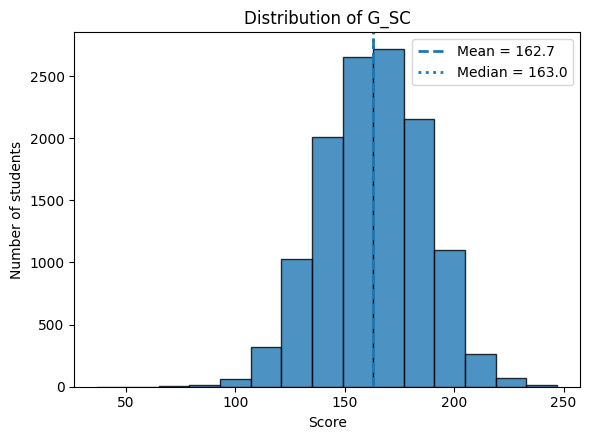

In [ ]:
### Global Score
plt.figure(figsize=(6, 4.5))

plt.hist(df["G_SC"], bins=15, edgecolor="black", alpha=0.8)

plt.axvline(
    df["G_SC"].mean(),
    linestyle="--",
    linewidth=2,
    label=f"Mean = {df['G_SC'].mean():.1f}"
)

plt.axvline(
    df["G_SC"].median(),
    linestyle=":",
    linewidth=2,
    label=f"Median = {df['G_SC'].median():.1f}"
)

plt.title("Distribution of G_SC")
plt.xlabel("Score")
plt.ylabel("Number of students")
plt.legend()

plt.tight_layout()
plt.show()

<Figure size 600x500 with 0 Axes>

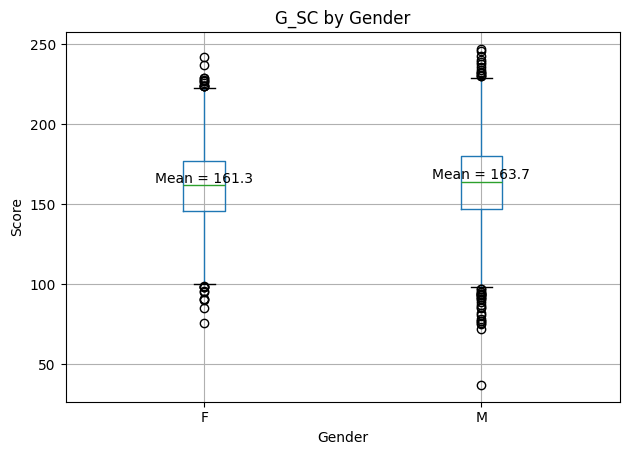

In [ ]:
plt.figure(figsize=(6, 5))

df.boxplot(
    column='G_SC',
    by='GENDER'
)

# Calculate means by gender
means = df.groupby('GENDER')['G_SC'].mean()

# Add mean labels
for i, (gender, mean) in enumerate(means.items(), start=1):
    plt.text(
        i,
        mean + 2,
        f"Mean = {mean:.1f}",
        ha='center'
    )

plt.title("G_SC by Gender")
plt.suptitle("")
plt.xlabel("Gender")
plt.ylabel("Score")

plt.tight_layout()
plt.show()

In [ ]:
counts = pd.crosstab(df["GENDER"], df["QUARTILE"])

percent = counts.div(counts.sum(axis=1), axis=0) * 100

result = counts.astype(str) + " (" + percent.round(1).astype(str) + "%)"

result

QUARTILE,1,2,3,4
GENDER,,,,
F,447 (8.9%),812 (16.1%),1352 (26.8%),2432 (48.2%)
M,577 (7.8%),1113 (15.1%),1793 (24.3%),3885 (52.7%)


Ok so male is doing slighly better overall than female students, what is the subjects they are particularly strong at?

In [ ]:
Test_S_11 = ['MAT_S11', 'CR_S11', 'CC_S11', 'ENG_S11']

Base_summary_G = df1.groupby('GENDER')[Test_S_11].describe().T

Base_summary_G

GENDER                   F            M
MAT_S11 count  5043.000000  7368.000000
        mean     61.932382    65.955483
        std      11.169655    12.063491
        min      31.000000    26.000000
        25%      54.000000    57.000000
        50%      61.000000    65.000000
        75%      69.000000    74.000000
        max     100.000000   100.000000
CR_S11  count  5043.000000  7368.000000
        mean     60.895300    60.698426
        std       9.873563    10.128695
        min      28.000000    24.000000
        25%      54.000000    54.000000
        50%      61.000000    61.000000
        75%      67.000000    67.000000
        max     100.000000   100.000000
CC_S11  count  5043.000000  7368.000000
        mean     59.959944    61.215255
        std       9.519411    10.482293
        min      29.000000     0.000000
        25%      53.000000    54.000000
        50%      60.000000    61.000000
        75%      66.000000    67.000000
        max     100.000000   100.000000
ENG_S11 count  5043.000000  7368.000000
        mean     61.451120    62.040581
        std      13.788398    14.632306
        min      26.000000    30.000000
        25%      50.000000    50.000000
        50%      59.000000    59.000000
        75%      70.000000    73.000000
        max     100.000000   100.000000

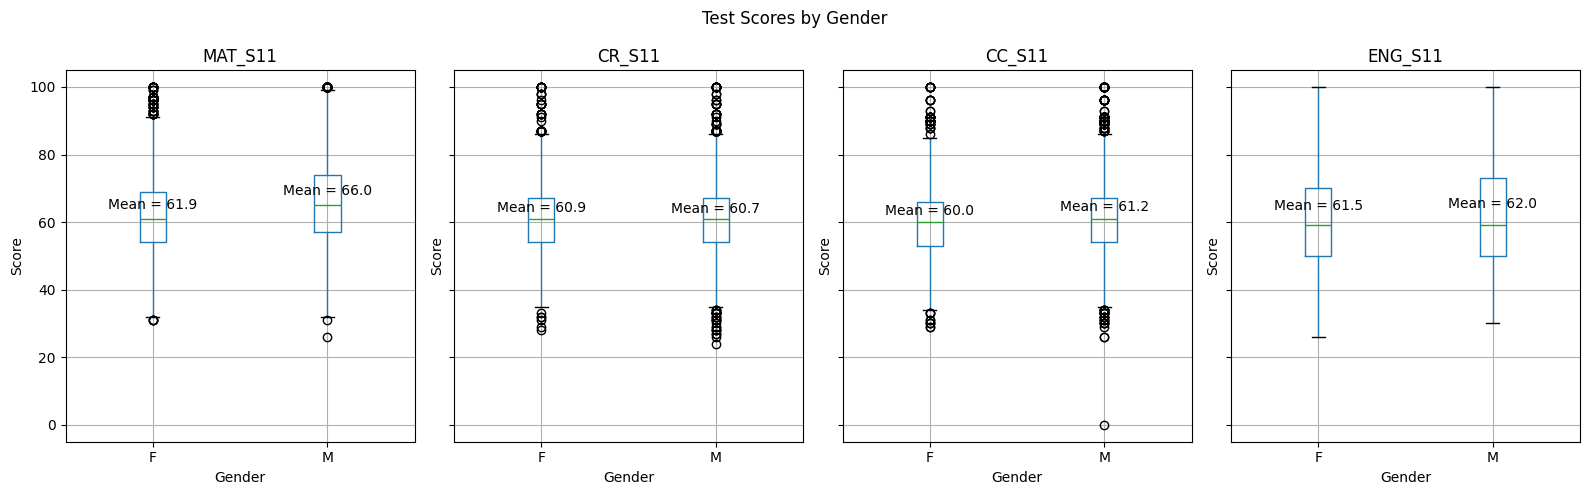

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(16, 5), sharey=True)
for ax, col in zip(axes, Test_S_11):

    df.boxplot(
        column=col,
        by='GENDER',
        ax=ax
    )

    # Calculate means by gender
    means = df.groupby('GENDER')[col].mean()

    # Add mean labels
    for i, (GENDER, mean) in enumerate(means.items(), start=1):
        ax.text(
            i,
            mean + 2,
            f"Mean = {mean:.1f}",
            ha='center'
        )

    ax.set_title(col)
    ax.set_xlabel("Gender")
    ax.set_ylabel("Score")

fig.suptitle("Test Scores by Gender")
plt.tight_layout()
plt.show()

Summary Statistics by gender (Pro)

In [ ]:
Test_Pro = ['QR_PRO','CR_PRO','CC_PRO','ENG_PRO']

End_summary_G = df1.groupby('GENDER')[Test_Pro].describe().T
End_summary_G

GENDER                   F            M
QR_PRO  count  5043.000000  7368.000000
        mean     71.892723    81.198561
        std      24.118522    20.801062
        min       1.000000     1.000000
        25%      56.000000    72.000000
        50%      78.000000    89.000000
        75%      92.000000    97.000000
        max     100.000000   100.000000
CR_PRO  count  5043.000000  7368.000000
        mean     61.338687    62.788409
        std      27.322031    27.886453
        min       1.000000     1.000000
        25%      41.000000    42.750000
        50%      66.000000    69.000000
        75%      85.000000    87.000000
        max     100.000000   100.000000
CC_PRO  count  5043.000000  7368.000000
        mean     58.573865    59.606270
        std      27.916715    29.699867
        min       1.000000     1.000000
        25%      36.000000    35.000000
        50%      63.000000    65.000000
        75%      83.000000    86.000000
        max     100.000000   100.000000
ENG_PRO count  5043.000000  7368.000000
        mean     66.532421    68.159473
        std      24.757032    25.969142
        min       1.000000     1.000000
        25%      51.000000    51.000000
        50%      72.000000    76.000000
        75%      87.000000    89.000000
        max     100.000000   100.000000

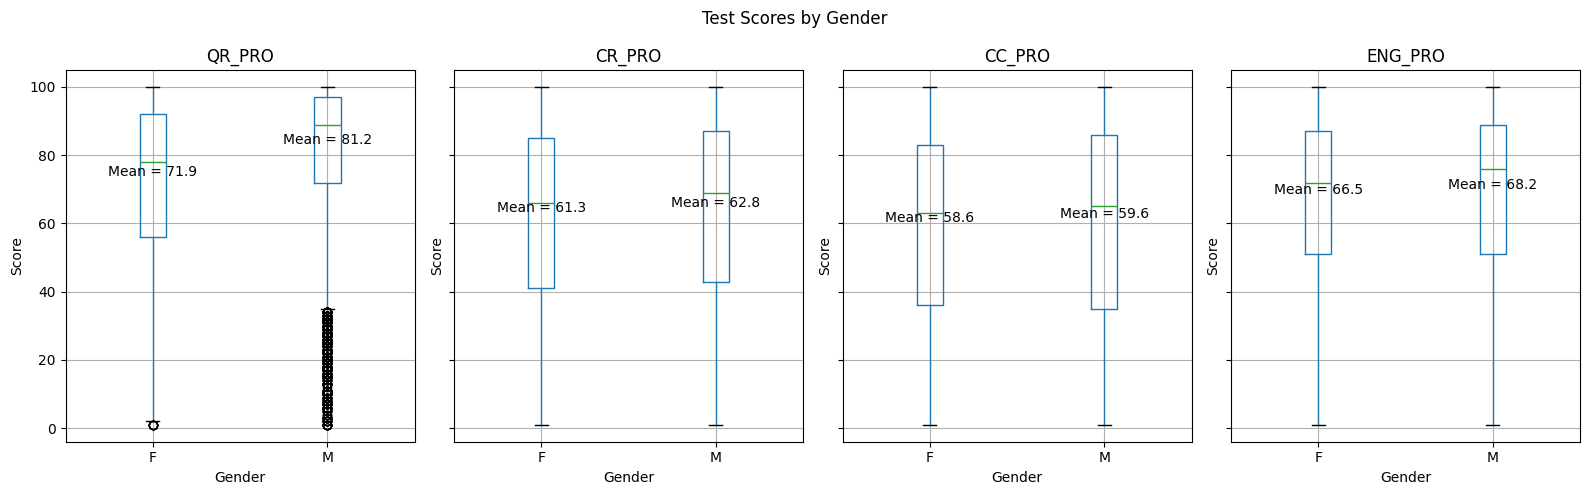

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(16, 5), sharey=True)
for ax, col in zip(axes, Test_Pro):

    df.boxplot(
        column=col,
        by='GENDER',
        ax=ax
    )

    # Calculate means by gender
    means = df.groupby('GENDER')[col].mean()

    # Add mean labels
    for i, (GENDER, mean) in enumerate(means.items(), start=1):
        ax.text(
            i,
            mean + 2,
            f"Mean = {mean:.1f}",
            ha='center'
        )

    ax.set_title(col)
    ax.set_xlabel("Gender")
    ax.set_ylabel("Score")

fig.suptitle("Test Scores by Gender")
plt.tight_layout()
plt.show()

Male has a wider spread with a slightly higher score than female test takers.

The gender difference is very small except for the quantitative test score. There is a wider gap in the S_11 level test than other subjects and the gap widen in the Pro level to 10 points. That could very likely contribute to the 2 points difference we see in the global score boxplot earlier.

# GENDER MOBILITY
We know now Male performs better in QR after finishing their degrees, how does this improvement dsitribute across good student and bad students when they graduated from high school?

In [ ]:
df_M = df[df["GENDER"] == "M"]

counts_M = pd.crosstab(df_M["Q_MATH"], df_M["Q_QR"])

percent_M = counts_M.div(counts_M.sum(axis=1), axis=0) * 100

result_M = counts_M.astype(str) + " (" + percent_M.round(1).astype(str) + "%)"

result_M



Q_QR,1,2,3,4
Q_MATH,,,,
1,880 (53.4%),487 (29.6%),229 (13.9%),52 (3.2%)
2,343 (18.3%),691 (36.9%),605 (32.3%),236 (12.6%)
3,118 (6.7%),395 (22.6%),727 (41.6%),509 (29.1%)
4,38 (1.8%),206 (9.8%),681 (32.5%),1171 (55.9%)


In [ ]:
df_F = df[df["GENDER"] == "F"]

counts_F = pd.crosstab(df_F["Q_MATH"], df_F["Q_QR"])

percent_F = counts_F.div(counts_F.sum(axis=1), axis=0) * 100

result_F = counts_F.astype(str) + " (" + percent_F.round(1).astype(str) + "%)"

result_F

Q_QR,1,2,3,4
Q_MATH,,,,
1,1134 (67.5%),391 (23.3%),133 (7.9%),22 (1.3%)
2,462 (31.7%),525 (36.0%),384 (26.4%),86 (5.9%)
3,111 (11.1%),294 (29.5%),398 (39.9%),195 (19.5%)
4,22 (2.4%),129 (14.2%),361 (39.8%),396 (43.6%)


Among male students, the 56% of top notch performers (tier-4) stay top-notch. The same best student group retainment rate is only 43.6%。

Male students improve to the best tier from upper-middle range group is 29% while the the same group for women is only 19.5%

for lower-middle range group, 45% of male students move into the upper class, 17% for the lowest score group on the S_11 level

for lower-middle range group, 32.3% of female students move into the upper class, 9.2% for the lowest score group on the S_11 level.

# Conclusion
**
Male students perform better than female students not only in both tests but improve to be better after the engineering education.

Nonetheless, given that highest percentage of people stay in their performance group after earning the engineering degree. It is reasonable to doubt there are other factors "trap" their scores and for which the engineering education can't mask.
**

# CAN HOUSEHOLD EDUCATION LEVEL EXPLAIN THE DIFFERENCE?

In [ ]:
### Cleaning the variables
df.columns
df.EDU_FATHER.value_counts()
df['EDU_FATHER'] = df['EDU_FATHER'].replace({0: 'N/A', 'Ninguno': 'N/A', 'Not sure': 'N/A'})

df.EDU_FATHER.value_counts()

,count
EDU_FATHER,
Complete professional education,3016
Complete Secundary,2843
Complete technique or technology,1194
Incomplete Secundary,1091
Postgraduate education,1085
N/A,921
Complete primary,824
Incomplete primary,735
Incomplete Professional Education,425


In [ ]:
df['EDU_MOTHER'] = df['EDU_MOTHER'].replace({0: 'N/A', 'Ninguno': 'N/A', 'Not sure': 'N/A'})

df.EDU_MOTHER.value_counts()

,count
EDU_MOTHER,
Complete Secundary,3106
Complete professional education,3059
Complete technique or technology,1495
Incomplete Secundary,1056
Postgraduate education,997
Complete primary,713
N/A,601
Incomplete primary,541
Incomplete Professional Education,502


# Classify the education levels into 4 tiers

In [ ]:
# Strip whitespace first to avoid missed matches
df = df1
df['EDU_FATHER'] = df['EDU_FATHER'].str.strip()

tier_map = {
    'Incomplete primary': '1',
    'Complete primary': '1',
    'Incomplete Secundary': '1',
    'Complete Secundary': '1',
    'Incomplete technical or technological': '2',
    'Complete technique or technology': '2',
    'Incomplete Professional Education': '3',
    'Complete professional education': '3',
    'Postgraduate education': '4',
}

df['TIER_ED_FA'] = df['EDU_FATHER'].map(tier_map)

df['TIER_ED_FA'].value_counts(dropna=False)

,count
TIER_ED_FA,
1,5493
3,3441
2,1471
4,1085
NaN,921


In [ ]:
df['EDU_MOTHER'] = df['EDU_MOTHER'].str.strip()

tier_map = {
    'Incomplete primary': '1',
    'Complete primary': '1',
    'Incomplete Secundary': '1',
    'Complete Secundary': '1',
    'Incomplete technical or technological': '2',
    'Complete technique or technology': '2',
    'Incomplete Professional Education': '3',
    'Complete professional education': '3',
    'Postgraduate education': '4',
}

df['TIER_ED_MO'] = df['EDU_MOTHER'].map(tier_map)

df['TIER_ED_MO'].value_counts(dropna=False)

,count
TIER_ED_MO,
1,5416
3,3561
2,1836
4,997
NaN,601


In [ ]:
df.head(20)

,COD_S11,GENDER,EDU_FATHER,EDU_MOTHER,OCC_FATHER,OCC_MOTHER,STRATUM,SISBEN,PEOPLE_HOUSE,Unnamed: 9,...,G_SC,PERCENTILE,2ND_DECILE,QUARTILE,SEL,SEL_IHE,Q_MATH,Q_QR,TIER_ED_FA,TIER_ED_MO
0,SB11201210000129,F,Incomplete Professional Education,Complete technique or technology,Technical or professional level employee,Home,Stratum 4,It is not classified by the SISBEN,Three,NaN,...,180,91,5,4,2,2,3,2,3,2
1,SB11201210000137,F,Complete Secundary,Complete professional education,Entrepreneur,Independent professional,Stratum 5,It is not classified by the SISBEN,Three,NaN,...,182,92,5,4,4,4,4,4,1,3
2,SB11201210005154,M,N/A,N/A,Independent,Home,Stratum 2,Level 2,Five,NaN,...,113,7,1,1,1,1,1,1,NaN,NaN
3,SB11201210007504,F,N/A,N/A,Other occupation,Independent,Stratum 2,It is not classified by the SISBEN,Three,NaN,...,157,67,4,3,2,2,1,1,NaN,NaN
4,SB11201210007548,M,Complete professional education,Complete professional education,Executive,Home,Stratum 4,It is not classified by the SISBEN,One,NaN,...,198,98,5,4,4,2,4,3,3,3
5,SB11201210007568,F,Complete professional education,Complete professional education,Independent,Executive,Stratum 6,It is not classified by the SISBEN,Three,NaN,...,154,63,4,3,4,2,3,3,3,3
6,SB11201210007598,M,Complete professional education,Complete professional education,Small entrepreneur,Executive,Stratum 5,It is not classified by the SISBEN,Four,NaN,...,152,59,3,3,2,2,3,2,3,3
7,SB11201210007615,F,Incomplete Secundary,Complete Secundary,Entrepreneur,Independent professional,Stratum 6,It is not classified by the SISBEN,Five,NaN,...,200,99,5,4,4,4,4,4,1,1
8,SB11201210010208,M,Complete Secundary,Complete professional education,Independent,Operator,Stratum 2,It is not classified by the SISBEN,Three,NaN,...,133,28,2,2,3,2,1,1,1,3
9,SB11201210013577,M,Incomplete technical or technological,Incomplete technical or technological,Independent,Home,Stratum 2,Level 2,Four,NaN,...,126,18,1,1,4,2,1,1,2,2


In [ ]:
df.groupby('TIER_ED_FA').agg({
    'QR_PRO': ['mean', 'std'],
    'CR_PRO': ['mean', 'std'],
    'CC_PRO': ['mean', 'std'],
    'ENG_PRO': ['mean', 'std']
})

QR_PRO                CR_PRO                CC_PRO             \
                 mean        std       mean        std       mean        std   
TIER_ED_FA                                                                     
1           74.030766  23.951744  57.833242  27.698720  54.985618  28.761830   
2           77.700884  22.226178  64.641740  26.862084  59.904827  28.977362   
3           80.455391  21.101743  65.957570  27.119545  63.334205  28.358337   
4           86.862673  16.769122  72.940092  25.481979  70.600922  27.130547   

              ENG_PRO             
                 mean        std  
TIER_ED_FA                        
1           59.827235  25.801532  
2           69.292998  23.531029  
3           74.936646  23.083155  
4           84.235945  18.237506

In [ ]:
df.groupby('TIER_ED_MO').agg({
    'QR_PRO': ['mean', 'std'],
    'CR_PRO': ['mean', 'std'],
    'CC_PRO': ['mean', 'std'],
    'ENG_PRO': ['mean', 'std']
})

QR_PRO                CR_PRO                CC_PRO             \
                 mean        std       mean        std       mean        std   
TIER_ED_MO                                                                     
1           74.013663  23.999719  57.766064  27.760586  54.918944  28.725849   
2           77.794118  21.854662  63.345316  26.879863  59.742919  28.758495   
3           80.782926  20.915434  66.666667  26.929920  63.610222  28.363377   
4           85.256770  18.041515  72.398195  25.505786  69.295888  27.663782   

              ENG_PRO             
                 mean        std  
TIER_ED_MO                        
1           59.615399  25.656952  
2           68.800109  23.984550  
3           75.796967  22.644717  
4           82.209629  20.323320

<Figure size 600x500 with 0 Axes>

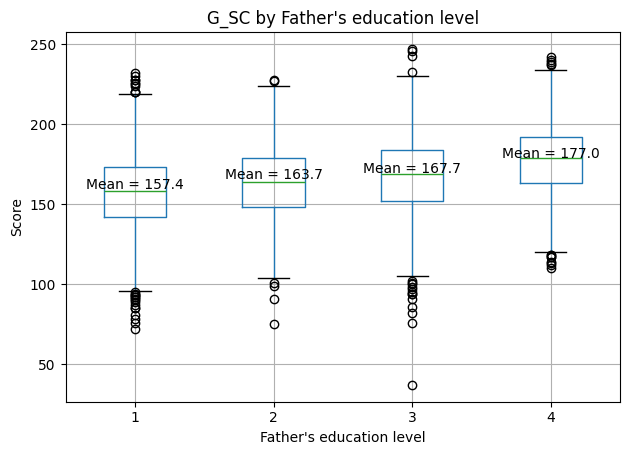

In [ ]:
plt.figure(figsize=(6, 5))

df.boxplot(
    column='G_SC',
    by='TIER_ED_FA'
)

# Calculate means by gender
means = df.groupby('TIER_ED_FA')['G_SC'].mean()

# Add mean labels
for i, (FA, mean) in enumerate(means.items(), start=1):
    plt.text(
        i,
        mean + 2,
        f"Mean = {mean:.1f}",
        ha='center'
    )

plt.title("G_SC by Father's education level")
plt.suptitle("")
plt.xlabel("Father's education level")
plt.ylabel("Score")

plt.tight_layout()
plt.show()

Now the global difference is more visible than the gender grouping. the higher the father's education the more likely the student going to achieve higher score. Again, the next step is to look deeper by the subjects.

<Figure size 600x500 with 0 Axes>

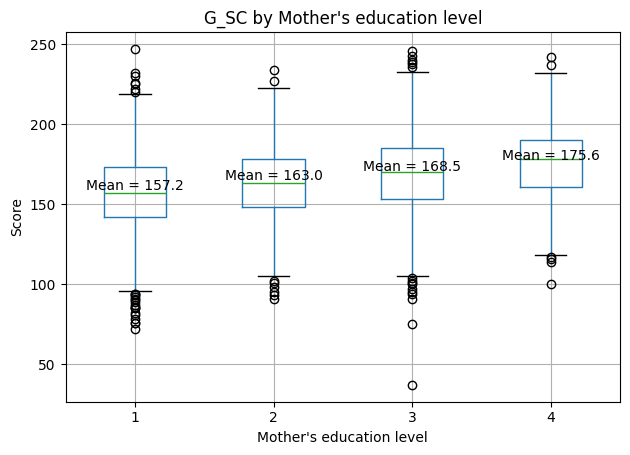

In [ ]:
plt.figure(figsize=(6, 5))

df.boxplot(
    column='G_SC',
    by='TIER_ED_MO'
)

# Calculate means by gender
means = df.groupby('TIER_ED_MO')['G_SC'].mean()

# Add mean labels
for i, (MO, mean) in enumerate(means.items(), start=1):
    plt.text(
        i,
        mean + 2,
        f"Mean = {mean:.1f}",
        ha='center'
    )

plt.title("G_SC by Mother's education level")
plt.suptitle("")
plt.xlabel("Mother's education level")
plt.ylabel("Score")

plt.tight_layout()
plt.show()

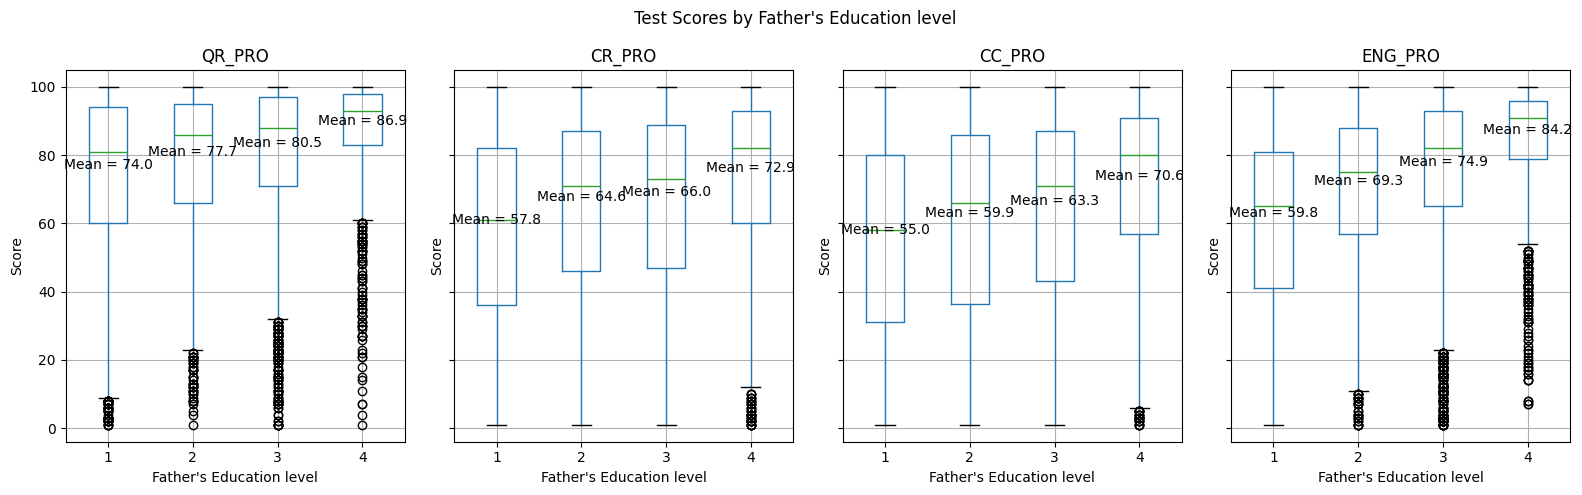

In [ ]:
Test_Pro = ['QR_PRO', 'CR_PRO', 'CC_PRO', 'ENG_PRO']

fig, axes = plt.subplots(1, 4, figsize=(16, 5), sharey=True)

for ax, col in zip(axes, Test_Pro):

    df.boxplot(
        column=col,
        by='TIER_ED_FA',
        ax=ax
    )

    # Calculate means by TIER_ED_FA
    means = df.groupby('TIER_ED_FA')[col].mean()

    # Add mean labels
    for i, (tier, mean) in enumerate(means.items(), start=1):
        ax.text(
            i,
            mean + 2,
            f"Mean = {mean:.1f}",
            ha='center'
        )

    ax.set_title(col)
    ax.set_xlabel("Father's Education level")
    ax.set_ylabel("Score")

fig.suptitle("Test Scores by Father's Education level")
plt.tight_layout()
plt.show()

The distribution become increasingly left skewed as the father's ecuation level becomes higher. In QR_PRO particularly, 50% of the students with a Postgraduate education father achieve higher than 93 points. The same pattern apply to English test, which is not very salient in the gender grouping.

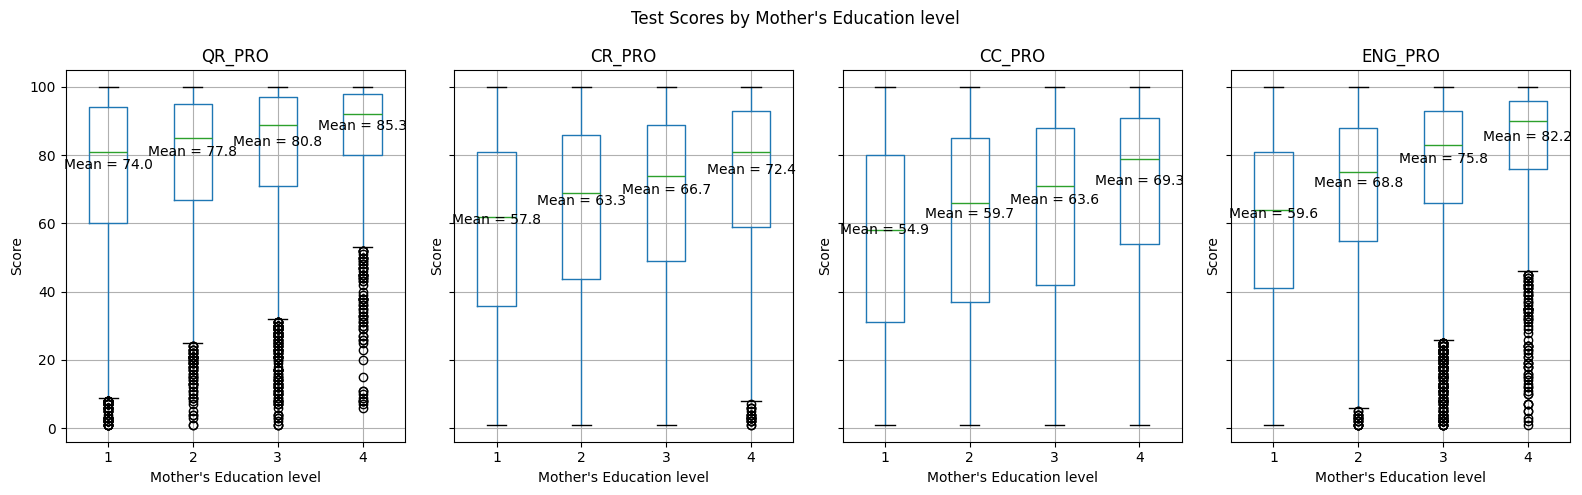

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(16, 5), sharey=True)

for ax, col in zip(axes, Test_Pro):

    df.boxplot(
        column=col,
        by='TIER_ED_MO',
        ax=ax
    )

    # Calculate means by TIER_ED_FA
    means = df.groupby('TIER_ED_MO')[col].mean()

    # Add mean labels
    for i, (tier, mean) in enumerate(means.items(), start=1):
        ax.text(
            i,
            mean + 2,
            f"Mean = {mean:.1f}",
            ha='center'
        )

    ax.set_title(col)
    ax.set_xlabel("Mother's Education level")
    ax.set_ylabel("Score")

fig.suptitle("Test Scores by Mother's Education level")
plt.tight_layout()
plt.show()

same pattern as the father education

# HOUSEHOLD EDUCATION BACKGROUND X GENDER

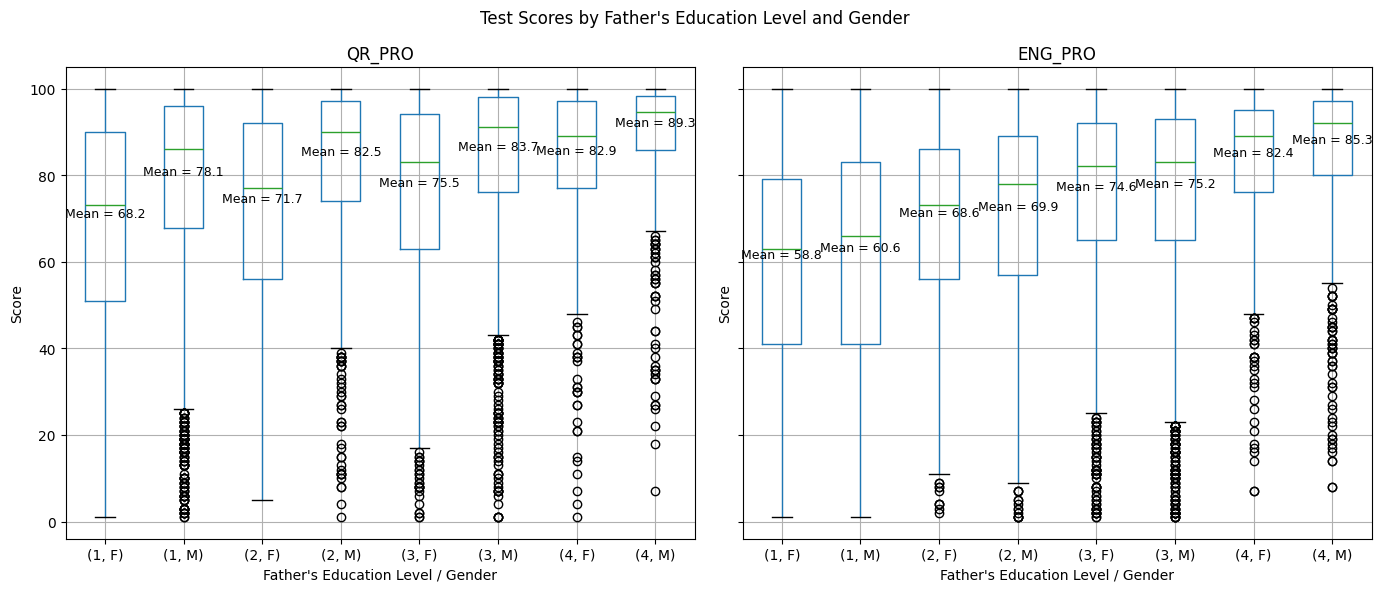

In [ ]:
Test_Pro = ['QR_PRO', 'ENG_PRO']

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

for ax, col in zip(axes, Test_Pro):

    df.boxplot(
        column=col,
        by=['TIER_ED_FA', 'GENDER'],
        ax=ax
    )

    # Calculate means for each education level and gender
    means = df.groupby(['TIER_ED_FA', 'GENDER'])[col].mean()

    # Add mean labels
    for i, ((tier, gender), mean) in enumerate(means.items(), start=1):
        ax.text(
            i,
            mean + 2,
            f"Mean = {mean:.1f}",
            ha='center',
            fontsize=9
        )

    ax.set_title(col)
    ax.set_xlabel("Father's Education Level / Gender")
    ax.set_ylabel("Score")

fig.suptitle("Test Scores by Father's Education Level and Gender")
plt.tight_layout()
plt.show()

As Expected, the male student with Postgraduate Education background is the best group in Math and English

In [ ]:
df.groupby( ['TIER_ED_FA','GENDER'])['QR_PRO'].median()

TIER_ED_FA  GENDER
1           F         73.0
            M         86.0
2           F         77.0
            M         90.0
3           F         83.0
            M         91.0
4           F         89.0
            M         94.5
Name: QR_PRO, dtype: float64

# HOUSEHOLD EDUCATION MOBILITY CHECK


In [ ]:
### Previously on mobility
counts = pd.crosstab(df["Q_MATH"], df["Q_QR"])

percent = counts.div(counts.sum(axis=1), axis=0) * 100

result = counts.astype(str) + " (" + percent.round(1).astype(str) + "%)"

result

Q_QR,1,2,3,4
Q_MATH,,,,
1,2014 (60.5%),878 (26.4%),362 (10.9%),74 (2.2%)
2,805 (24.2%),1216 (36.5%),989 (29.7%),322 (9.7%)
3,229 (8.3%),689 (25.1%),1125 (41.0%),704 (25.6%)
4,60 (2.0%),335 (11.2%),1042 (34.7%),1567 (52.2%)


now I'm only interest in cells (Q_MATH== 4,Q_QR==4), (Q_MATH== 3,Q_QR==4), (Q_MATH== 2,Q_QR==3), and (Q_MATH== 2,Q_QR==4), the students who improve

and see in each cells, how each household education level are being represented

In [ ]:
cells = [
    (4, 4),
    (3, 4),
    (2, 3),
    (2, 4)
]

# Total count of each TIER_ED_FA level
total_tier = df["TIER_ED_FA"].value_counts().sort_index()

for math, qr in cells:

    subset = df[
        (df["Q_MATH"] == math) &
        (df["Q_QR"] == qr)
    ]

    # Count within this Q_MATH × Q_QR cell
    counts = subset["TIER_ED_FA"].value_counts().sort_index()

    # % within this Q_MATH × Q_QR cell
    percent = counts / counts.sum() * 100

    # % of each TIER_ED_FA level that is in this Q_MATH × Q_QR cell
    percent_total = counts / total_tier * 100

    result = pd.DataFrame({
        "Count": counts,
        "Percent": percent.round(1),
        "Percent_total": percent_total.round(1)
    })

    print(f"\nQ_MATH = {math}, Q_QR = {qr}")
    print(result)


Q_MATH = 4, Q_QR = 4
            Count  Percent  Percent_total
TIER_ED_FA                               
1             469     31.4            8.5
2             166     11.1           11.3
3             589     39.4           17.1
4             270     18.1           24.9

Q_MATH = 3, Q_QR = 4
            Count  Percent  Percent_total
TIER_ED_FA                               
1             281     42.3            5.1
2              98     14.8            6.7
3             199     30.0            5.8
4              86     13.0            7.9

Q_MATH = 2, Q_QR = 3
            Count  Percent  Percent_total
TIER_ED_FA                               
1             450     49.8            8.2
2             136     15.0            9.2
3             253     28.0            7.4
4              65      7.2            6.0

Q_MATH = 2, Q_QR = 4
            Count  Percent  Percent_total
TIER_ED_FA                               
1             147     50.7            2.7
2              35     12.1    

In [ ]:
df['TIER_ED_FA'].value_counts(dropna=False)

,count
TIER_ED_FA,
1,5493
3,3441
2,1471
4,1085
NaN,921


At first glance, the students come from the lowest education level's household are the majority of the improvment class. However, It is due to the absolute sample size difference at the beginning of constructing tiers of father's education. When the proportion is calculated by using TIER_ED_FA's within level counts as the denominator, the dominance of higher education family background shows immediately.

almost 25% of the Postgraduate Education family's student stay excellence through and through, 17% of the professional education background for the same group. Despite the overall sample size drop, as the plain mobility table shows that the improvment itself is not very common, higher education family background remain top in its proportion to the overall population within the (Q_MATH = 3, Q_QR = 4) cell.

This pattern disappear when the starting point of the student is the lower middle score range (Q_MATH = 2). It is very likely because there are few higher education famility's students in this corhort in the first place.

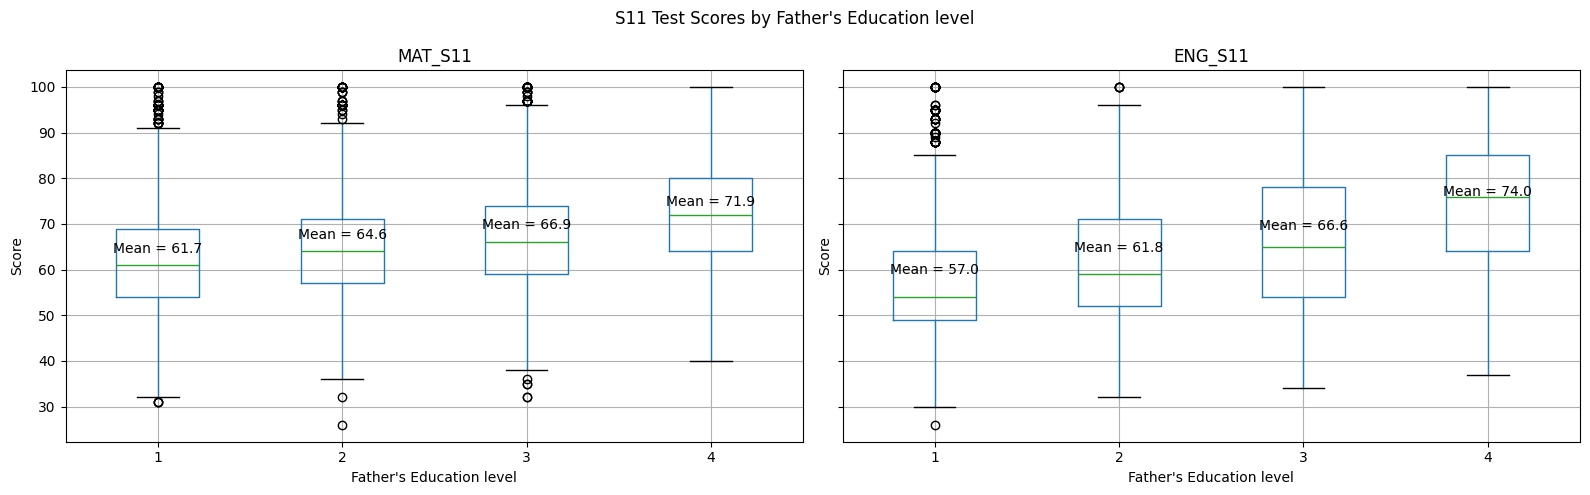

In [ ]:
Core_S_11 = ['MAT_S11', 'ENG_S11']

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

for ax, col in zip(axes, Core_S_11):

    df.boxplot(
        column=col,
        by='TIER_ED_FA',
        ax=ax
    )

    # Calculate means by TIER_ED_FA
    means = df.groupby('TIER_ED_FA')[col].mean()

    # Add mean labels
    for i, (tier, mean) in enumerate(means.items(), start=1):
        ax.text(
            i,
            mean + 2,
            f"Mean = {mean:.1f}",
            ha='center'
        )

    ax.set_title(col)
    ax.set_xlabel("Father's Education level")
    ax.set_ylabel("Score")

fig.suptitle("S11 Test Scores by Father's Education level")
plt.tight_layout()
plt.show()